# Notebook 03 – Huấn luyện và so sánh mô hình (bảng T6, T6b, T7, T8 và hình)
Notebook này **không viết lại logic làm sạch**: nó gọi `clean` và `lay_ban` (cleaning.py), rồi gọi `src/sparkmind/modeling.py` (mô hình, chạy CV, tóm tắt) và `src/sparkmind/ve_hinh.py` (vẽ hình).

**Mục tiêu:** xem các đặc trưng hành vi dùng LLM có dự đoán được **mức** năng lực sáng tạo **tự nhận thức** (Thấp / Trung bình / Cao, chia từ C1–C5 tự chấm) tốt hơn việc đoán bừa hay không. Đây **không** phải đo năng lực sáng tạo bằng bài kiểm tra.

**Quy tắc chống sai sót (đã kiểm tra tự động bằng code):**
- Đầu vào chỉ gồm: lớp, giới tính, cấp học (one-hot), B2, B5, B4_1..B4_7 (số gốc, không đảo chiều), B1/B3/B6/B7 (0/1) và B1_so, B3_so, B6_so.
- **Cấm** đưa vào: C1..C5, diem_sang_tao, muc, C6, C6_so, dot, nguon, thoi_gian, các cột in_*, co_*, tên trường, id. Hàm `kiem_tra_cot_cam` sẽ báo lỗi nếu lọt cột cấm.
- Điền thiếu, chuẩn hóa, one-hot nằm **trong pipeline** và chỉ học trên phần train của từng fold (không rò rỉ).
- `random_state = 42`, không dò tham số. Số của các bản dữ liệu (361 / 297 / 231) **không trộn** trong cùng một bảng.

## 1. Nạp dữ liệu và chuẩn bị

In [1]:
import sys; sys.path.append('../src')
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sparkmind import config, modeling as M
from sparkmind.cleaning import clean, lay_ban
from sparkmind.loaders import doc_excel, doc_goc_mongo
from sparkmind.db import lay_db
from sparkmind.ve_hinh import ve_boxplot_macro_f1, ve_cot_lobo

NGUON = 'excel'   # đổi thành 'mongo' khi dữ liệu đã nằm trong MongoDB
raw = doc_excel() if NGUON == 'excel' else doc_goc_mongo(lay_db())
sach = clean(raw)   # gắn cờ chất lượng, không xóa form nào
BANG = config.ROOT / 'outputs' / 'tables'; HINH = config.ROOT / 'outputs' / 'figures'
BANG.mkdir(parents=True, exist_ok=True); HINH.mkdir(parents=True, exist_ok=True)

def luu(bang, ten, hien=True):
    """Lưu bảng CSV (UTF-8 có BOM để Excel đọc được tiếng Việt) rồi hiện ra (làm tròn 3 số lẻ)."""
    bang.to_csv(BANG / ten, index=False, encoding='utf-8-sig')
    if hien: display(bang.round(3))

# Ba bản dữ liệu. reset_index để X, y, ban có cùng chỉ số 0..n-1.
BAN = {k: lay_ban(sach, k).reset_index(drop=True) for k in ('chinh', 'chat', 'rat_chat')}
CHINH = config.BAN_CHINH   # bản chính của báo cáo = 'chat' (297)

## A. Kiểm tra dữ liệu và đặc trưng
Trước khi huấn luyện, kiểm tra: đúng số dòng của 3 bản, phân bố 3 mức, danh sách đặc trưng, và thử xem hàm kiểm tra cột cấm có hoạt động không.

In [2]:
assert (len(BAN['chinh']), len(BAN['chat']), len(BAN['rat_chat'])) == (361, 297, 231)
assert CHINH == 'chat'
print('Số dòng: bản rộng 361 (chinh), bản chính 297 (chat), bản rất chặt 231 (rat_chat) -> đúng')

# Phân bố 3 mức của TỪNG bản (mỗi bản một nhóm dòng riêng, không trộn số)
phan_bo = M.phan_bo_muc({'rong_361_chinh': BAN['chinh'], 'chinh_297_chat': BAN['chat'], 'rat_chat_231': BAN['rat_chat']})
luu(phan_bo, 'T6_label_distribution.csv')
print('Số dòng theo đợt (bản chính 297):'); display(BAN['chat']['dot'].value_counts().to_frame('so_dong'))

Số dòng: bản rộng 361 (chinh), bản chính 297 (chat), bản rất chặt 231 (rat_chat) -> đúng


,ban,muc,n,ty_le_%
0,rong_361_chinh,Thap,119,33.0
1,rong_361_chinh,Trung_binh,150,41.6
2,rong_361_chinh,Cao,92,25.5
3,chinh_297_chat,Thap,103,34.7
4,chinh_297_chat,Trung_binh,119,40.1
5,chinh_297_chat,Cao,75,25.3
6,rat_chat_231,Thap,97,42.0
7,rat_chat_231,Trung_binh,98,42.4
8,rat_chat_231,Cao,36,15.6


Số dòng theo đợt (bản chính 297):


,so_dong
dot,
dot2_16/9,173
dot3_4-5/11,93
dot1_rai_rac,31


In [3]:
X_chinh = M.tao_dac_trung(BAN[CHINH])
print('Số đặc trưng:', X_chinh.shape[1], '| số dòng:', X_chinh.shape[0])
dt = pd.DataFrame({'dac_trung': X_chinh.columns,
                   'kieu': ['chữ -> one-hot' if c in M.COT_PHAN_LOAI else 'số' for c in X_chinh.columns],
                   'so_o_thieu_ban_chinh': X_chinh.isna().sum().values})
luu(dt, 'T6_features.csv')
luu(M.phien_ban_thu_vien(), 'T6_versions.csv')

# Thử cố tình đưa C1 vào: PHẢI báo lỗi
try:
    M.kiem_tra_cot_cam(list(X_chinh.columns) + ['C1'])
    raise SystemExit('LỖI: hàm kiểm tra không chặn C1!')
except ValueError as e:
    print('Đúng như mong đợi, hàm chặn cột cấm:', e)

Số đặc trưng: 35 | số dòng: 297


,dac_trung,kieu,so_o_thieu_ban_chinh
0,lop_so,số,0
1,A2_nu,số,0
2,A2_khac,số,0
3,cap_hoc,chữ -> one-hot,0
4,B2_so,số,0
5,B5_so,số,0
6,B4_1,số,0
7,B4_2,số,0
8,B4_3,số,0
9,B4_4,số,0


,thu_vien,phien_ban
0,python,3.12.10
1,numpy,2.5.5
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,xgboost,3.4.1
5,random_state,42


Đúng như mong đợi, hàm chặn cột cấm: Cột BỊ CẤM trong bảng đặc trưng: ['C1']


## B. Kiểm định chéo lặp 5 lớp × 10 lần trên bản chính (297) – bảng T6
**Cách đọc:**
- **Macro-F1** (chỉ số chính): trung bình F1 của 3 mức, mỗi mức có trọng số bằng nhau. Đoán ngẫu nhiên khoảng 0.33; mô hình "luôn đoán mức phổ biến nhất" chỉ khoảng 0.19.
- Mỗi mô hình được thử 50 lần (5 fold × 10 lần lặp); cột `_sd` là độ lệch chuẩn giữa 50 lần, cột `_ci` là **khoảng 95%** của trung bình tính bằng bootstrap (lấy mẫu lại 2000 lần trên 50 giá trị fold, lấy phân vị 2.5% và 97.5%).
- **Lưu ý:** các fold của các lần lặp dùng lại cùng một nhóm người nên **không độc lập hoàn toàn**; khoảng 95% này thường **hẹp hơn thực tế** và chỉ là *khoảng tham khảo*.
- Tất cả mô hình dùng **cùng một cách chia fold**, nên so sánh ghép cặp theo fold là hợp lệ.

In [4]:
def chay_ban(khoa, hau_to):
    """Chạy CV 5x10 cho một bản: phân loại (muc) và hồi quy phụ (diem_sang_tao). Lưu bảng fold và trả về kết quả."""
    ban = BAN[khoa]; X = M.tao_dac_trung(ban); y_lop, y_diem = M.tao_nhan(ban)
    chia = M.tao_cac_lan_chia(y_lop)          # 50 lần chia, dùng chung cho mọi mô hình
    assert len(chia) == 50
    cot = M._cot_so(X)
    f_lop = M.chay_cv(X, y_lop, M.tao_mo_hinh_phan_loai(cot), chia, 'lop')
    f_diem = M.chay_cv(X, y_diem, M.tao_mo_hinh_hoi_quy(cot), chia, 'diem')
    f_lop.to_csv(BANG / f'T6_cv_folds_classification_{hau_to}.csv', index=False, encoding='utf-8-sig')
    f_diem.to_csv(BANG / f'T6_cv_folds_regression_{hau_to}.csv', index=False, encoding='utf-8-sig')
    return X, y_lop, chia, f_lop, f_diem

In [5]:
X, y_lop, chia, f_lop, f_diem = chay_ban(CHINH, 'strict')
print('Bản chính 297 dòng. Phân loại 3 mức (macro-F1 là chỉ số chính):')
t6 = M.tom_tat(f_lop, ['macro_f1', 'bal_acc', 'acc'])
luu(t6, 'T6_cv_classification_strict.csv')

Bản chính 297 dòng. Phân loại 3 mức (macro-F1 là chỉ số chính):


,mo_hinh,so_fold,macro_f1_tb,macro_f1_sd,macro_f1_ci_thap,macro_f1_ci_cao,bal_acc_tb,bal_acc_sd,bal_acc_ci_thap,bal_acc_ci_cao,acc_tb,acc_sd,acc_ci_thap,acc_ci_cao
0,Dummy phổ biến nhất,50,0.191,0.002,0.190,0.191,0.333,0.000,0.333,0.333,0.401,0.006,0.399,0.402
1,Dummy theo tỉ lệ,50,0.316,0.055,0.300,0.331,0.317,0.055,0.302,0.332,0.335,0.058,0.319,0.351
2,Logistic,50,0.608,0.060,0.591,0.625,0.618,0.061,0.601,0.635,0.604,0.059,0.588,0.621
3,Random Forest,50,0.659,0.060,0.643,0.677,0.661,0.059,0.645,0.679,0.659,0.058,0.644,0.676
4,XGBoost,50,0.628,0.057,0.613,0.643,0.631,0.057,0.616,0.646,0.623,0.054,0.609,0.638


In [6]:
print('Hồi quy phụ (điểm 0–100): R2 càng gần 1 càng tốt (R2 ≈ 0 là ngang đoán trung bình); MAE là sai số tuyệt đối trung bình (điểm).')
t6r = M.tom_tat(f_diem, ['r2', 'mae'])
luu(t6r, 'T6_cv_regression_strict.csv')

Hồi quy phụ (điểm 0–100): R2 càng gần 1 càng tốt (R2 ≈ 0 là ngang đoán trung bình); MAE là sai số tuyệt đối trung bình (điểm).


,mo_hinh,so_fold,r2_tb,r2_sd,r2_ci_thap,r2_ci_cao,mae_tb,mae_sd,mae_ci_thap,mae_ci_cao
0,Dummy trung bình,50,-0.003,0.004,-0.004,-0.002,14.953,0.753,14.753,15.168
1,Ridge,50,0.518,0.073,0.496,0.537,10.205,0.779,9.998,10.428
2,Random Forest,50,0.515,0.072,0.495,0.535,10.054,0.911,9.801,10.298
3,XGBoost,50,0.503,0.072,0.482,0.523,10.362,0.810,10.129,10.581


### So sánh ghép cặp theo fold (hiệu macro-F1 = A trừ B)
`hieu_tb` > 0 nghĩa là A tốt hơn B trung bình. `ci_chua_0 = True` nghĩa là khoảng 95% **không chứa 0**. Nhớ đây là *khoảng tham khảo* vì các fold không độc lập hoàn toàn. `ty_le_fold_A_hon_B` là tỉ lệ trong 50 fold mà A hơn B.

In [7]:
cap = [('XGBoost', 'Dummy phổ biến nhất'), ('XGBoost', 'Dummy theo tỉ lệ'), ('XGBoost', 'Logistic'),
       ('Random Forest', 'Dummy phổ biến nhất'), ('Random Forest', 'Dummy theo tỉ lệ'), ('Random Forest', 'Logistic'),
       ('Logistic', 'Dummy theo tỉ lệ'), ('XGBoost', 'Random Forest')]
t6p = M.so_sanh_ghep(f_lop, 'macro_f1', cap)
luu(t6p, 'T6_paired_strict.csv')

,so_sanh,chi_so,hieu_tb,ci_thap,ci_cao,ty_le_fold_A_hon_B,ci_chua_0
0,XGBoost - Dummy phổ biến nhất,macro_f1,0.437,0.422,0.453,1.00,True
1,XGBoost - Dummy theo tỉ lệ,macro_f1,0.312,0.292,0.331,1.00,True
2,XGBoost - Logistic,macro_f1,0.020,0.004,0.036,0.58,True
3,Random Forest - Dummy phổ biến nhất,macro_f1,0.468,0.452,0.486,1.00,True
4,Random Forest - Dummy theo tỉ lệ,macro_f1,0.343,0.323,0.363,1.00,True
5,Random Forest - Logistic,macro_f1,0.051,0.035,0.068,0.74,True
6,Logistic - Dummy theo tỉ lệ,macro_f1,0.292,0.270,0.314,1.00,True
7,XGBoost - Random Forest,macro_f1,-0.031,-0.045,-0.019,0.22,True


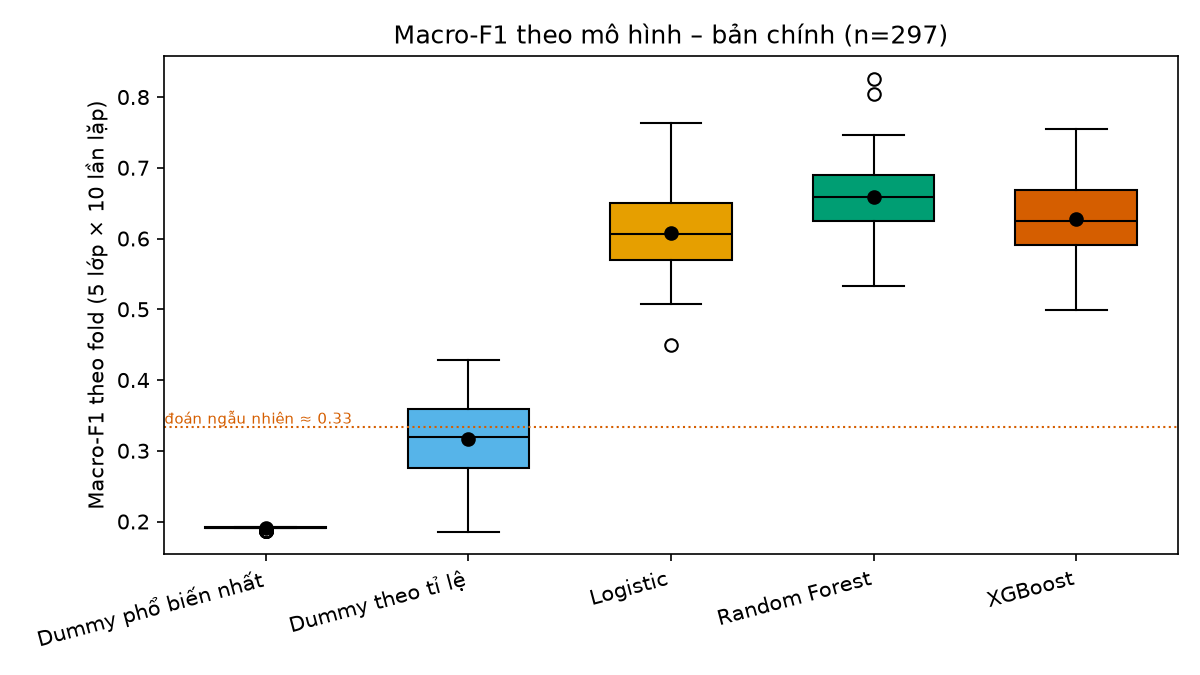

In [8]:
# Hình: boxplot macro-F1 theo mô hình (bản chính 297)
ve_boxplot_macro_f1(f_lop, 'Macro-F1 theo mô hình – bản chính (n=297)', HINH / 'fig_model_boxplot_macro_f1_strict.png')
display(Image(HINH / 'fig_model_boxplot_macro_f1_strict.png'))

### Kiểm tra rò rỉ bằng nhãn xáo trộn
Xáo ngẫu nhiên nhãn `muc` rồi chạy lại CV. Nếu pipeline không rò rỉ thì macro-F1 phải quanh **0.33** (đoán ngẫu nhiên). Nếu cao hơn nhiều là có lỗi.

In [9]:
y_xao = np.random.default_rng(M.RANDOM_STATE).permutation(y_lop)
mh2 = {k: v for k, v in M.tao_mo_hinh_phan_loai(M._cot_so(X)).items() if k in ('Random Forest', 'XGBoost')}
f_xao = M.chay_cv(X, y_xao, mh2, M.tao_cac_lan_chia(y_xao, n_lap=3), 'lop')
t_xao = M.tom_tat(f_xao, ['macro_f1'])
luu(t_xao, 'T6_permutation_check_strict.csv')
assert t_xao['macro_f1_tb'].max() < 0.45, 'Nhãn xáo trộn mà điểm cao -> nghi rò rỉ!'

,mo_hinh,so_fold,macro_f1_tb,macro_f1_sd,macro_f1_ci_thap,macro_f1_ci_cao
0,Random Forest,15,0.349,0.074,0.313,0.385
1,XGBoost,15,0.310,0.063,0.278,0.341


## C. Lặp lại cho bản rộng (361) và bản rất chặt (231) – bảng T6b
Mỗi bản **một bảng riêng**, không trộn. **Bản 231 chỉ để đối chiếu**: bộ lọc "rất chặt" dùng chính B4_3 và B4_4 (cờ mâu thuẫn), nên bản này đã bị chọn theo một phần đặc trưng đầu vào và số có thể đẹp hơn do cách lọc, không hẳn do dữ liệu tốt hơn.

In [10]:
phu = {}
for khoa, hau_to in (('chinh', 'main'), ('rat_chat', 'very_strict')):
    _, _, _, fl, fd = chay_ban(khoa, hau_to)
    phu[khoa] = (fl, fd)

In [11]:
print('Bản rộng 361 (khóa chinh) – phân loại:')
luu(M.tom_tat(phu['chinh'][0], ['macro_f1', 'bal_acc', 'acc']), 'T6b_cv_classification_main.csv')
print('Bản rộng 361 – hồi quy phụ:')
luu(M.tom_tat(phu['chinh'][1], ['r2', 'mae']), 'T6b_cv_regression_main.csv')

Bản rộng 361 (khóa chinh) – phân loại:


,mo_hinh,so_fold,macro_f1_tb,macro_f1_sd,macro_f1_ci_thap,macro_f1_ci_cao,bal_acc_tb,bal_acc_sd,bal_acc_ci_thap,bal_acc_ci_cao,acc_tb,acc_sd,acc_ci_thap,acc_ci_cao
0,Dummy phổ biến nhất,50,0.196,0.001,0.195,0.196,0.333,0.000,0.333,0.333,0.416,0.002,0.415,0.416
1,Dummy theo tỉ lệ,50,0.326,0.050,0.312,0.341,0.328,0.049,0.314,0.342,0.349,0.049,0.335,0.363
2,Logistic,50,0.628,0.042,0.616,0.639,0.640,0.044,0.628,0.652,0.622,0.043,0.611,0.634
3,Random Forest,50,0.677,0.050,0.664,0.691,0.678,0.051,0.665,0.692,0.674,0.050,0.660,0.687
4,XGBoost,50,0.632,0.049,0.618,0.646,0.636,0.050,0.622,0.649,0.627,0.048,0.613,0.639


Bản rộng 361 – hồi quy phụ:


,mo_hinh,so_fold,r2_tb,r2_sd,r2_ci_thap,r2_ci_cao,mae_tb,mae_sd,mae_ci_thap,mae_ci_cao
0,Dummy trung bình,50,-0.003,0.003,-0.004,-0.002,15.831,0.847,15.595,16.070
1,Ridge,50,0.513,0.086,0.489,0.537,10.796,0.881,10.553,11.045
2,Random Forest,50,0.548,0.064,0.530,0.565,10.480,0.950,10.218,10.732
3,XGBoost,50,0.518,0.071,0.497,0.536,10.749,0.913,10.506,11.000


In [12]:
print('Bản rất chặt 231 (khóa rat_chat; chỉ đối chiếu) – phân loại:')
luu(M.tom_tat(phu['rat_chat'][0], ['macro_f1', 'bal_acc', 'acc']), 'T6b_cv_classification_very_strict.csv')
print('Bản rất chặt 231 – hồi quy phụ:')
luu(M.tom_tat(phu['rat_chat'][1], ['r2', 'mae']), 'T6b_cv_regression_very_strict.csv')

Bản rất chặt 231 (khóa rat_chat; chỉ đối chiếu) – phân loại:


,mo_hinh,so_fold,macro_f1_tb,macro_f1_sd,macro_f1_ci_thap,macro_f1_ci_cao,bal_acc_tb,bal_acc_sd,bal_acc_ci_thap,bal_acc_ci_cao,acc_tb,acc_sd,acc_ci_thap,acc_ci_cao
0,Dummy phổ biến nhất,50,0.194,0.001,0.194,0.195,0.333,0.000,0.333,0.333,0.411,0.004,0.410,0.412
1,Dummy theo tỉ lệ,50,0.342,0.076,0.321,0.362,0.346,0.071,0.326,0.365,0.414,0.075,0.394,0.435
2,Logistic,50,0.565,0.081,0.543,0.589,0.586,0.090,0.562,0.612,0.582,0.071,0.563,0.603
3,Random Forest,50,0.632,0.078,0.610,0.654,0.627,0.077,0.606,0.648,0.665,0.060,0.649,0.681
4,XGBoost,50,0.588,0.062,0.571,0.606,0.588,0.065,0.571,0.606,0.605,0.050,0.591,0.619


Bản rất chặt 231 – hồi quy phụ:


,mo_hinh,so_fold,r2_tb,r2_sd,r2_ci_thap,r2_ci_cao,mae_tb,mae_sd,mae_ci_thap,mae_ci_cao
0,Dummy trung bình,50,-0.005,0.006,-0.007,-0.004,14.312,1.042,14.028,14.598
1,Ridge,50,0.384,0.128,0.347,0.418,11.237,1.089,10.946,11.544
2,Random Forest,50,0.427,0.103,0.397,0.453,10.708,1.002,10.432,10.968
3,XGBoost,50,0.430,0.113,0.398,0.460,10.812,0.990,10.540,11.067


## D. Leave-one-batch-out (LOBO) trên bản chính – bảng T7
**Ý tưởng:** lần lượt giữ lại **MỘT đợt thu** làm tập thử, huấn luyện trên các đợt còn lại. Cách này kiểm tra mô hình có còn đúng khi gặp **nhóm người thu theo cách khác** hay không (đợt thuê hàng loạt so với form tự nhiên). Cột `dot` chỉ dùng để chia nhóm, **không** là đặc trưng. Đợt dưới 15 dòng chỉ báo số dòng.

**Lưu ý:** mỗi đợt chỉ có **một** lần thử (không lặp), đợt nhỏ thì kết quả rất dao động; đừng đọc chênh lệch nhỏ giữa các mô hình.

In [13]:
ban_c = BAN[CHINH]
print('Số dòng và phân bố mức theo đợt (bản chính 297):')
dd = ban_c.groupby('dot')['muc'].value_counts().unstack(fill_value=0).reindex(columns=M.MUC_THU_TU)
dd.insert(0, 'so_dong', dd.sum(axis=1)); display(dd.reset_index())
print('Các đợt có trong dữ liệu:', sorted(ban_c['dot'].unique()), '(file Excel không có dot4, dot5)')

Số dòng và phân bố mức theo đợt (bản chính 297):


muc,dot,so_dong,Thap,Trung_binh,Cao
0,dot1_rai_rac,31,10,12,9
1,dot2_16/9,173,59,68,46
2,dot3_4-5/11,93,34,39,20


Các đợt có trong dữ liệu: ['dot1_rai_rac', 'dot2_16/9', 'dot3_4-5/11'] (file Excel không có dot4, dot5)


In [14]:
t7 = M.lobo(ban_c, X, 'lop')
luu(t7, 'T7_lobo_classification_strict.csv')

,dot_thu,n_thu,n_train,mo_hinh,macro_f1,bal_acc,acc
0,dot1_rai_rac,31,266,Dummy phổ biến nhất,0.186,0.333,0.387
1,dot1_rai_rac,31,266,Dummy theo tỉ lệ,0.324,0.337,0.355
2,dot1_rai_rac,31,266,Logistic,0.492,0.530,0.516
3,dot1_rai_rac,31,266,Random Forest,0.560,0.607,0.613
4,dot1_rai_rac,31,266,XGBoost,0.510,0.552,0.548
5,dot2_16/9,173,124,Dummy phổ biến nhất,0.188,0.333,0.393
6,dot2_16/9,173,124,Dummy theo tỉ lệ,0.306,0.304,0.306
7,dot2_16/9,173,124,Logistic,0.519,0.515,0.520
8,dot2_16/9,173,124,Random Forest,0.568,0.568,0.578
9,dot2_16/9,173,124,XGBoost,0.560,0.558,0.561


Hồi quy phụ theo LOBO:


,dot_thu,n_thu,n_train,mo_hinh,r2,mae
0,dot1_rai_rac,31,266,Dummy trung bình,-0.013,14.109
1,dot1_rai_rac,31,266,Ridge,-0.074,13.448
2,dot1_rai_rac,31,266,Random Forest,0.036,12.662
3,dot1_rai_rac,31,266,XGBoost,-0.036,13.530
4,dot2_16/9,173,124,Dummy trung bình,-0.022,15.123
5,dot2_16/9,173,124,Ridge,0.357,11.980
6,dot2_16/9,173,124,Random Forest,0.505,10.339
7,dot2_16/9,173,124,XGBoost,0.461,10.823
8,dot3_4-5/11,93,204,Dummy trung bình,-0.038,15.105
9,dot3_4-5/11,93,204,Ridge,0.585,9.726


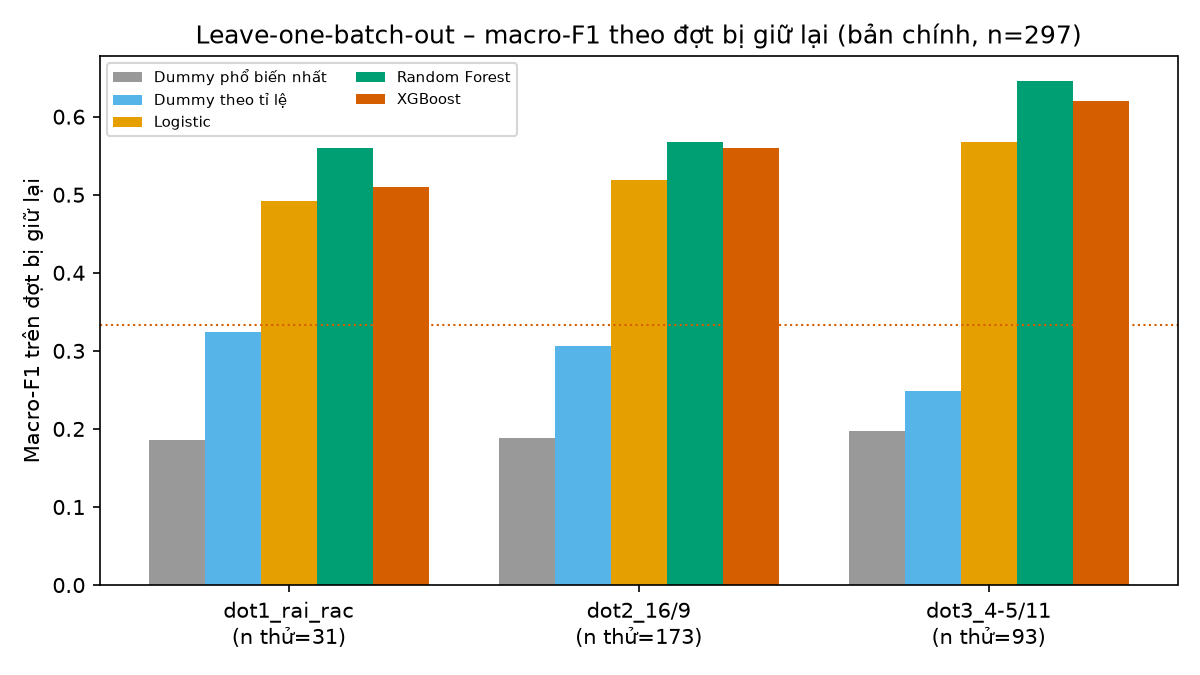

In [15]:
print('Hồi quy phụ theo LOBO:')
t7r = M.lobo(ban_c, X, 'diem')
luu(t7r, 'T7_lobo_regression_strict.csv')
ve_cot_lobo(t7, 'Leave-one-batch-out – macro-F1 theo đợt bị giữ lại (bản chính, n=297)', HINH / 'fig_lobo_macro_f1_strict.png')
display(Image(HINH / 'fig_lobo_macro_f1_strict.png'))

## E. Thử độc lập: huấn luyện trên đợt thu hàng loạt, thử trên form tự nhiên – bảng T8
Huấn luyện trên **dot2 và dot3** (đợt thu hàng loạt), thử trên **dot1, dot4, dot5** (form tự nhiên, nếu có đủ ≥ 15 dòng). Cỡ mẫu từng phần ghi ở `n_train` và `n_thu`.

In [16]:
t8 = M.thu_doc_lap(ban_c, X, ['dot2_16/9', 'dot3_4-5/11'], ['dot1_rai_rac', 'dot4_sau_5_11', 'dot5_form_v2'])
luu(t8, 'T8_independent_strict.csv')

,mo_hinh,macro_f1,bal_acc,acc,dot_thu,n_thu,n_train
0,Dummy phổ biến nhất,0.186,0.333,0.387,dot1_rai_rac,31,266
1,Dummy theo tỉ lệ,0.324,0.337,0.355,dot1_rai_rac,31,266
2,Logistic,0.492,0.530,0.516,dot1_rai_rac,31,266
3,Random Forest,0.560,0.607,0.613,dot1_rai_rac,31,266
4,XGBoost,0.510,0.552,0.548,dot1_rai_rac,31,266
5,(không đủ dòng),NaN,NaN,NaN,dot4_sau_5_11,0,266
6,(không đủ dòng),NaN,NaN,NaN,dot5_form_v2,0,266


**Ghi chú:** file dữ liệu hiện chỉ có 3 đợt (dot1, dot2, dot3), nên bảng T8 chỉ có một phần thử là dot1, và **trùng với dòng "dot1" của T7** (vì lúc đó "các đợt còn lại" chính là dot2 + dot3). Khi dữ liệu có thêm dot4, dot5 (từ MongoDB) thì bảng T8 sẽ tự thêm các dòng đó. Dot1 chỉ khoảng 31 dòng nên kết quả rất dao động.

## F. Phân tích bổ sung (KHÔNG phải kết quả chính): thêm C6_so vào đặc trưng
C6 là mức hoạt động sáng tạo trong 12 tháng qua. C6 bị **loại** khỏi danh sách đặc trưng chính vì nó thuộc khối đo sáng tạo (khối C), không phải hành vi dùng LLM; đưa vào sẽ làm lẫn "hành vi LLM" với "kinh nghiệm sáng tạo". Ở đây chỉ **xem thay đổi** nếu thêm vào (bản chính, cùng cách chia fold).

In [17]:
X6 = M.tao_dac_trung(BAN[CHINH], cho_phep=('C6_so',))   # chỉ lần này mới được phép có C6_so
print('Số đặc trưng:', X.shape[1], '->', X6.shape[1], '| C6_so thiếu:', int(X6['C6_so'].isna().sum()), 'dòng (điền trung vị trong pipeline)')
f6 = M.chay_cv(X6, y_lop, M.tao_mo_hinh_phan_loai(M._cot_so(X6)), chia, 'lop', cho_phep=('C6_so',))
f6.to_csv(BANG / 'T6c_cv_folds_with_C6_strict.csv', index=False, encoding='utf-8-sig')
a = M.tom_tat(f_lop, ['macro_f1']).set_index('mo_hinh'); b = M.tom_tat(f6, ['macro_f1']).set_index('mo_hinh')
t6c = pd.DataFrame({'macro_f1_khong_C6': a['macro_f1_tb'], 'macro_f1_co_C6': b['macro_f1_tb']})
t6c['thay_doi'] = t6c['macro_f1_co_C6'] - t6c['macro_f1_khong_C6']
luu(t6c.reset_index(), 'T6c_with_C6_strict.csv')

Số đặc trưng: 35 -> 36 | C6_so thiếu: 1 dòng (điền trung vị trong pipeline)


,mo_hinh,macro_f1_khong_C6,macro_f1_co_C6,thay_doi
0,Dummy phổ biến nhất,0.191,0.191,0.000
1,Dummy theo tỉ lệ,0.316,0.316,0.000
2,Logistic,0.608,0.599,-0.008
3,Random Forest,0.659,0.666,0.007
4,XGBoost,0.628,0.622,-0.006


In [18]:
# Hiệu macro-F1 ghép cặp theo fold: (có C6) trừ (không C6), cho từng mô hình
g = pd.concat([f_lop.assign(mo_hinh=f_lop['mo_hinh'] + ' | không C6'), f6.assign(mo_hinh=f6['mo_hinh'] + ' | có C6')])
cap6 = [(m + ' | có C6', m + ' | không C6') for m in ('Logistic', 'Random Forest', 'XGBoost')]
luu(M.so_sanh_ghep(g, 'macro_f1', cap6), 'T6c_paired_with_C6_strict.csv')

,so_sanh,chi_so,hieu_tb,ci_thap,ci_cao,ty_le_fold_A_hon_B,ci_chua_0
0,Logistic | có C6 - Logistic | không C6,macro_f1,-0.008,-0.016,-0.001,0.34,True
1,Random Forest | có C6 - Random Forest | không C6,macro_f1,0.007,-0.001,0.014,0.46,False
2,XGBoost | có C6 - XGBoost | không C6,macro_f1,-0.006,-0.014,0.001,0.34,False


## G2. Bỏ từng nhóm biến (ablation) trên bản chính (297) – bảng T9
**Để làm gì:** xem nhóm biến nào đang "gánh" kết quả. Mỗi cấu hình chạy lại CV 5×10 với **đúng các lần chia** của bảng T6, chỉ 3 mô hình (Logistic, Random Forest, XGBoost). Hồi quy phụ dùng Ridge thay cho Logistic (cùng họ tuyến tính). Cấu hình "Đủ biến" phải **trùng** bảng T6 (có kiểm tra bên dưới). Cột cấm vẫn bị chặn bằng `kiem_tra_cot_cam`.

In [19]:
cauhinh = M.cau_hinh_ablation()
for ten, cot in cauhinh.items():
    M.kiem_tra_cot_cam(cot)          # mọi cấu hình đều qua kiểm tra cột cấm
print({k: len(v) for k, v in cauhinh.items()})
ab_lop, ab_diem = M.chay_ablation(BAN[CHINH], chia)
ab_lop.to_csv(BANG / 'T9_ablation_folds_classification_strict.csv', index=False, encoding='utf-8-sig')
ab_diem.to_csv(BANG / 'T9_ablation_folds_regression_strict.csv', index=False, encoding='utf-8-sig')

# Kiểm tra: "Đủ biến" phải bằng T6 gốc (cùng chia, cùng tham số)
dv = ab_lop[ab_lop['cau_hinh'] == 'Đủ biến'].groupby('mo_hinh')['macro_f1'].mean()
for m in dv.index:
    assert abs(dv[m] - t6.set_index('mo_hinh').loc[m, 'macro_f1_tb']) < 1e-9, f'Đủ biến khác T6 ở {m}'
print('Đủ biến trùng T6 -> đúng')

{'Đủ biến': 35, 'Bỏ B4': 28, 'Chỉ có B4': 7, 'Bỏ B1/B3/B6/B7': 13, 'Chỉ thông tin nền': 4, 'Bỏ B2 và B5': 33}


Đủ biến trùng T6 -> đúng


In [20]:
def tom_ab(f, chi_so):
    g = f.groupby(['cau_hinh', 'mo_hinh'], sort=False)[chi_so].mean().rename(f'{chi_so}_tb').reset_index()
    return g
a_f1 = tom_ab(ab_lop, 'macro_f1'); a_r2 = tom_ab(ab_diem, 'r2')
t9 = a_f1.merge(a_r2, on=['cau_hinh', 'mo_hinh'], how='outer')
t9['so_cot'] = t9['cau_hinh'].map({k: len(v) for k, v in cauhinh.items()})
t9['mo_hinh'] = pd.Categorical(t9['mo_hinh'], ['Logistic', 'Ridge', 'Random Forest', 'XGBoost'])
rong = a_f1.pivot(index='cau_hinh', columns='mo_hinh', values='macro_f1_tb').reindex(list(cauhinh))
rong2 = a_r2.pivot(index='cau_hinh', columns='mo_hinh', values='r2_tb').reindex(list(cauhinh))
t9w = rong.add_prefix('macro_f1 ').join(rong2.add_prefix('R2 ')).reset_index()
t9w.insert(1, 'so_cot', t9w['cau_hinh'].map({k: len(v) for k, v in cauhinh.items()}))
print('Bảng T9 (macro-F1: Logistic/RF/XGBoost; R2 hồi quy: Ridge/RF/XGBoost), bản chính 297, CV 5x10:')
luu(t9w, 'T9_ablation_strict.csv')

Bảng T9 (macro-F1: Logistic/RF/XGBoost; R2 hồi quy: Ridge/RF/XGBoost), bản chính 297, CV 5x10:


mo_hinh,cau_hinh,so_cot,macro_f1 Logistic,macro_f1 Random Forest,macro_f1 XGBoost,R2 Random Forest,R2 Ridge,R2 XGBoost
0,Đủ biến,35,0.608,0.659,0.628,0.515,0.518,0.503
1,Bỏ B4,28,0.431,0.436,0.424,0.014,-0.021,-0.118
2,Chỉ có B4,7,0.619,0.658,0.633,0.512,0.547,0.477
3,Bỏ B1/B3/B6/B7,13,0.606,0.651,0.612,0.506,0.533,0.429
4,Chỉ thông tin nền,4,0.349,0.341,0.349,-0.009,0.039,-0.017
5,Bỏ B2 và B5,33,0.612,0.660,0.627,0.519,0.527,0.511


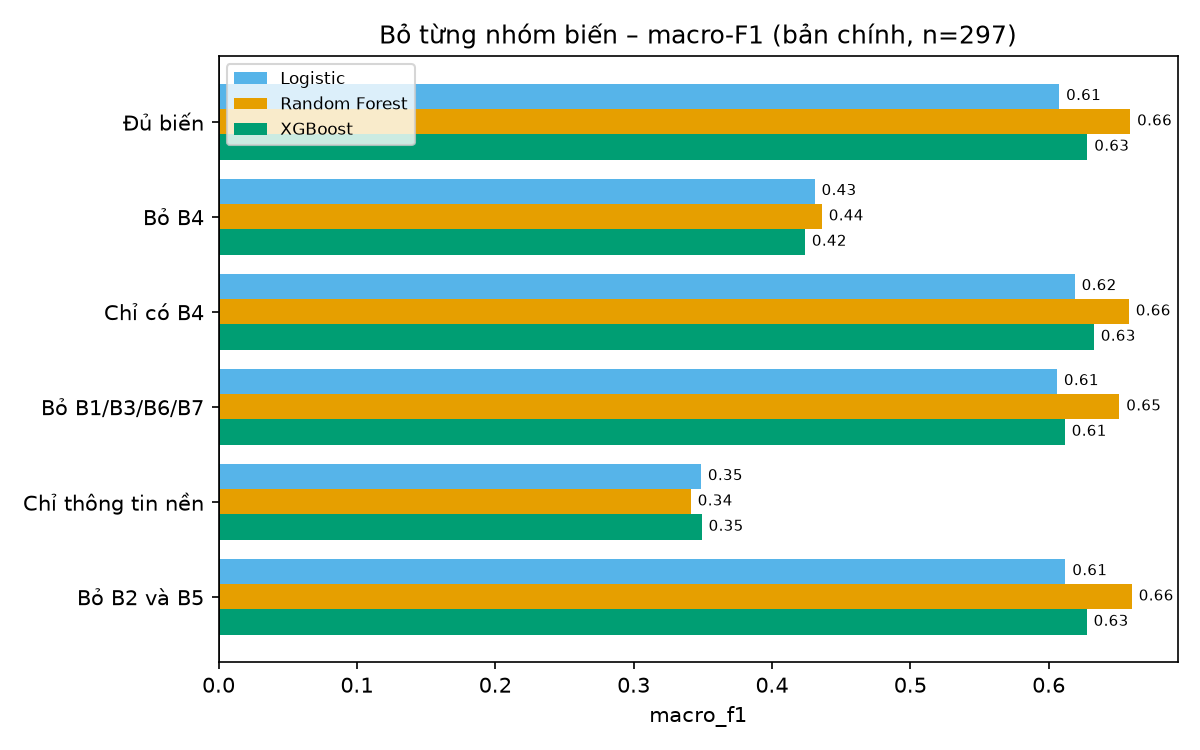

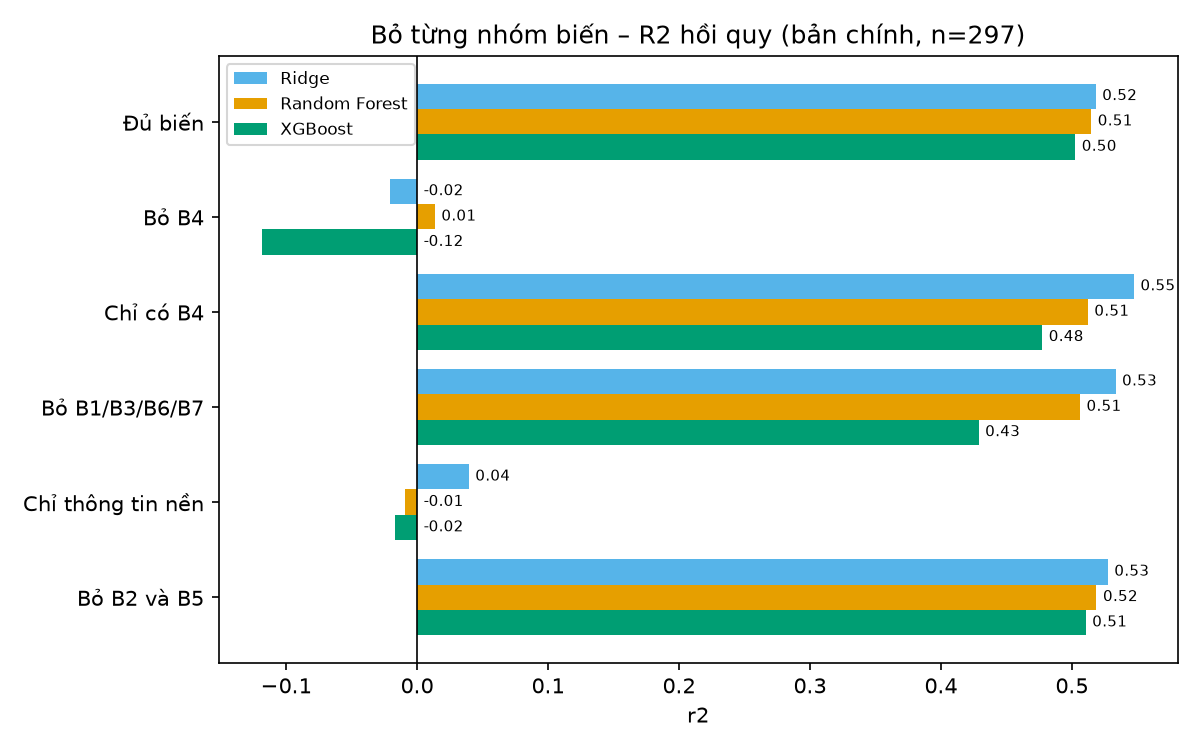

In [21]:
from sparkmind.ve_hinh import ve_cot_ablation
ve_cot_ablation(a_f1, 'macro_f1', 'Bỏ từng nhóm biến – macro-F1 (bản chính, n=297)', HINH / 'fig_ablation_macro_f1_strict.png')
display(Image(HINH / 'fig_ablation_macro_f1_strict.png'))
ve_cot_ablation(a_r2, 'r2', 'Bỏ từng nhóm biến – R2 hồi quy (bản chính, n=297)', HINH / 'fig_ablation_r2_strict.png')
display(Image(HINH / 'fig_ablation_r2_strict.png'))

## G3. Chẩn đoán đợt dot1 (31 dòng)
Chỉ **in số liệu**, không suy đoán: phân bố 3 mức của dot1 và các đợt còn lại, ma trận nhầm lẫn của Random Forest khi giữ lại dot1 (huấn luyện trên dot2+dot3, đúng như dòng dot1 của T7), và macro-F1 của "Dummy theo tỉ lệ" trên đúng tập dot1.

In [22]:
DOT1 = 'dot1_rai_rac'
dp = ban_c.assign(nhom=np.where(ban_c['dot'] == DOT1, 'dot1', 'các đợt còn lại')).groupby('nhom')['muc'].value_counts().unstack(fill_value=0).reindex(columns=M.MUC_THU_TU)
dp['so_dong'] = dp.sum(axis=1)
for m in M.MUC_THU_TU: dp[f'{m}_%'] = (100 * dp[m] / dp['so_dong']).round(1)
print('Phân bố 3 mức: dot1 và các đợt còn lại (bản chính 297):'); luu(dp.reset_index(), 'T9b_dot1_label_distribution_strict.csv')
cd = M.chan_doan_dot(ban_c, X, DOT1)
print('Ma trận nhầm lẫn Random Forest khi giữ lại dot1 (hàng = thật, cột = đoán), n =', cd['n_thu'])
luu(cd['ma_tran'].reset_index().rename(columns={'index': 'thuc_te'}), 'T9b_dot1_confusion_rf_strict.csv')
print(f"macro-F1 Random Forest trên dot1: {cd['f1_rf']:.3f}")
print(f"macro-F1 Dummy theo tỉ lệ trên dot1: lần chạy trong LOBO (random_state=42) = {cd['dummy_lan_lobo']:.3f}; "
      f"trung bình 200 hạt giống = {cd['dummy_tb']:.3f} (độ lệch chuẩn {cd['dummy_sd']:.3f})")

Phân bố 3 mức: dot1 và các đợt còn lại (bản chính 297):


muc,nhom,Thap,Trung_binh,Cao,so_dong,Thap_%,Trung_binh_%,Cao_%
0,các đợt còn lại,93,107,66,266,35.0,40.2,24.8
1,dot1,10,12,9,31,32.3,38.7,29.0


Ma trận nhầm lẫn Random Forest khi giữ lại dot1 (hàng = thật, cột = đoán), n = 31


,thuc_te,doan_Thap,doan_Trung_binh,doan_Cao
0,that_Thap,1,9,0
1,that_Trung_binh,1,10,1
2,that_Cao,0,1,8


macro-F1 Random Forest trên dot1: 0.560
macro-F1 Dummy theo tỉ lệ trên dot1: lần chạy trong LOBO (random_state=42) = 0.324; trung bình 200 hạt giống = 0.320 (độ lệch chuẩn 0.088)


**Vì sao F1 có thể khác R2 ở tập nhỏ này (chỉ nêu cách tính):**
1. Macro-F1 chỉ nhìn **nhãn đoán đúng/sai** theo từng mức rồi lấy trung bình 3 mức bằng nhau; một mức chỉ có vài người thì chỉ vài lần đoán đúng/sai cũng làm F1 của mức đó, và cả macro-F1, nhảy mạnh.
2. R2 nhìn **khoảng cách điểm 0–100** so với việc đoán trung bình của chính tập thử; khi điểm trong dot1 ít phân tán hơn hoặc khác trung bình của tập huấn luyện thì R2 có thể gần 0 hoặc âm dù nhãn mức vẫn đoán đúng một phần (và ngược lại).
3. Với 31 dòng, cả hai chỉ số chỉ dựa trên một lần thử, nên sai lệch ngẫu nhiên lớn và hai chỉ số không cần thay đổi cùng chiều.

## H. Kết luận (viết bằng lời, sau khi xem kết quả)

Viết lại ngày 23/11/2026 sau khi có kết quả bỏ nhóm biến (G2) và chẩn đoán dot1 (G3), theo dữ liệu hiện có (file Excel, 460 form). Số có thể đổi khi dữ liệu tăng; chạy lại notebook thì phần chữ này cần đọc lại.

1. **Hơn đoán bừa, chênh giữa mô hình nhỏ.** Trên bản chính (297), cả ba mô hình đều hơn hẳn hai đường cơ sở: macro-F1 khoảng 0.61 (Logistic), 0.63 (XGBoost), 0.66 (Random Forest), so với 0.19 (luôn đoán mức phổ biến) và 0.32 (đoán theo tỉ lệ). Chênh giữa ba mô hình nhỏ (Random Forest hơn Logistic khoảng 0.05, hơn XGBoost khoảng 0.03) và khoảng 95% chỉ là tham khảo vì các fold không độc lập hoàn toàn, nên chưa xếp hạng chắc. Hồi quy phụ cho R2 khoảng 0.50–0.52, sai số khoảng 10 điểm. Phép thử xáo trộn nhãn cho macro-F1 khoảng 0.31–0.35, không thấy dấu hiệu rò rỉ.
2. **Tín hiệu nằm ở nhóm câu B4.** (T9) Chỉ dùng 7 câu B4 cho kết quả gần bằng dùng đủ biến (Random Forest 0.658 so với 0.659). Bỏ B4 thì macro-F1 còn khoảng 0.43 và R2 khoảng 0. Bỏ nhóm B1/B3/B6/B7 (công cụ, mục đích, cách viết câu lệnh, cách xử lý kết quả) hoặc bỏ B2/B5 (tần suất, thời lượng) gần như không đổi kết quả, tức các biến về mục đích và tần suất không thêm thông tin trong dữ liệu này. Chỉ dùng thông tin nền (lớp, giới, cấp học) cho macro-F1 khoảng 0.34, ngang đoán bừa.
3. **Có thể có xu hướng trả lời chung.** B4 và điểm sáng tạo đều là tự đánh giá, trả lời cùng một lần. Cả B4_3 và B4_6 (hai câu tiêu cực) vẫn tương quan dương với điểm. Điều này phù hợp với việc một phần liên hệ đến từ cách trả lời chung, nhưng notebook này chưa kiểm tra giả thuyết đó. Kết quả chỉ nói về **liên hệ dự đoán**, không nói về nguyên nhân.
4. **Nhóm tự nhiên (dot1) chỉ có 31 dòng, bằng chứng lẫn lộn.** Khi giữ lại dot1, Random Forest cho macro-F1 0.56 (đúng 19/31), dummy theo tỉ lệ trung bình 0.32 (độ lệch chuẩn 0.09); nhưng R2 hồi quy gần 0 (từ −0.07 đến 0.04). Hai chỉ số không cùng chiều và chỉ có một lần thử với 31 dòng, nên chưa kết luận về nhóm tự nhiên. Trong ma trận nhầm lẫn, mức Thấp phần lớn bị đoán thành Trung bình (9/10).
5. **Thử độc lập (T8)** hiện chỉ có dot1 làm tập thử (file chưa có dot4, dot5), trùng dòng dot1 của T7. Cần chạy lại với `NGUON = 'mongo'` sau khi chốt dữ liệu (khoảng 22/12).
6. **Các bản dữ liệu khác.** Bản rộng (361) cho số tương tự (Random Forest khoảng 0.68); bản rất chặt (231, chỉ đối chiếu vì bộ lọc dùng B4_3, B4_4) thấp hơn (khoảng 0.63) với phân bố mức khác. Không so trực tiếp số giữa các bản. Thêm C6_so (phân tích bổ sung) đổi macro-F1 trong khoảng ±0.01.
7. **Cần kiểm chứng bằng dữ liệu độc lập:** form tự nhiên mới (dot4, dot5) và điểm các trò chơi của hướng 2, vì các điểm này không cùng một lần tự khai với B4.
8. **Giới hạn cần ghi vào báo cáo:** biến đầu ra là năng lực sáng tạo **tự nhận thức**; đầu vào cũng tự khai trong cùng một bảng hỏi; mẫu nhỏ (297); không dò tham số; chỉ mô tả khả năng dự đoán.